In [ ]:
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import periodictable
import seaborn as sns

from moleculecs.data_utils import PreprocessedGraphDataset
from transformers import AutoModel, AutoTokenizer
from pprint import pprint

In [2]:
train_data = "../data/raw/train_graphs.pkl"
val_path = "../data/raw/validation_graphs.pkl"
test_path = "../data/raw/test_graphs.pkl"

In [3]:
train_data = PreprocessedGraphDataset(train_data)
val_data = PreprocessedGraphDataset(val_path)
test_data = PreprocessedGraphDataset(test_path)

Loading graphs from: ../data/raw/train_graphs.pkl
Loaded 31008 graphs
Loading graphs from: ../data/raw/validation_graphs.pkl
Loaded 1000 graphs
Loading graphs from: ../data/raw/test_graphs.pkl
Loaded 1000 graphs


In [4]:
len(train_data), len(val_data), len(test_data)

(31008, 1000, 1000)

# Graph size distribution

## Node / edge statistics (train + val)

In [5]:
num_nodes = [data.x.size(0) for data in train_data]
num_edges = [data.edge_index.size(1) // 2 for data in train_data]

In [6]:
print("======== Nodes ==================")
print(
    f"min:  {min(num_nodes)} \nmax: {max(num_nodes)}\nmean: {np.mean(num_nodes)}\nmedian: {np.median(num_nodes)} "
)
min(num_nodes), max(num_nodes), np.mean(num_nodes), np.median(num_nodes)
print(
    f"90th percentile : {np.percentile(num_nodes, 90)} \n95th percentile : {np.percentile(num_nodes, 95)}\n99th percentile : {np.percentile(num_nodes, 99)}"
)

print("======== Edges ==================")
print(
    f"min:  {min(num_edges)} \nmax: {max(num_edges)}\nmean: {np.mean(num_edges)}\nmedian: {np.median(num_edges)} "
)
min(num_edges), max(num_edges), np.mean(num_edges), np.median(num_edges)
print(
    f"90th percentile : {np.percentile(num_edges, 90)} \n95th percentile : {np.percentile(num_edges, 95)}\n99th percentile : {np.percentile(num_edges, 99)}"
)

======== Nodes ==================
min:  1 
max: 574
mean: 32.08617131062952
median: 25.0 
90th percentile : 61.0 
95th percentile : 76.0
99th percentile : 137.0
======== Edges ==================
min:  0 
max: 642
mean: 33.37171052631579
median: 26.0 
90th percentile : 63.0 
95th percentile : 80.0
99th percentile : 144.0


## Node count vs description length

In [7]:
description_lenght = [len(data.description) for data in train_data]

In [8]:
print("Correlation\n", np.corrcoef(num_nodes, description_lenght))

Correlation
 [[1.         0.19452721]
 [0.19452721 1.        ]]


# Node and edge feature usage

## Node Features

In [9]:
# 1. Aggregate atomic numbers from your dataset
atomic_nums = []
for data in train_data:
    # data.x[:, 0] usually contains the atomic numbers in PyTorch Geometric
    atomic_nums.extend(data.x[:, 0].tolist())

# 2. Map atomic numbers to element symbols
atom_counts_raw = Counter(atomic_nums)
atom_counts = {periodictable.elements[k].symbol: v for k, v in atom_counts_raw.items()}

df = pd.DataFrame(list(atom_counts.items()), columns=["Element", "Count"])  # ty:ignore[invalid-argument-type]
df = df.sort_values("Count", ascending=False).reset_index(drop=True)
df.head(10)

,Element,Count
0,C,674188
1,O,238592
2,N,56848
3,P,10481
4,S,6902
5,Cl,3022
6,F,2510
7,Br,565
8,Na,456
9,I,299


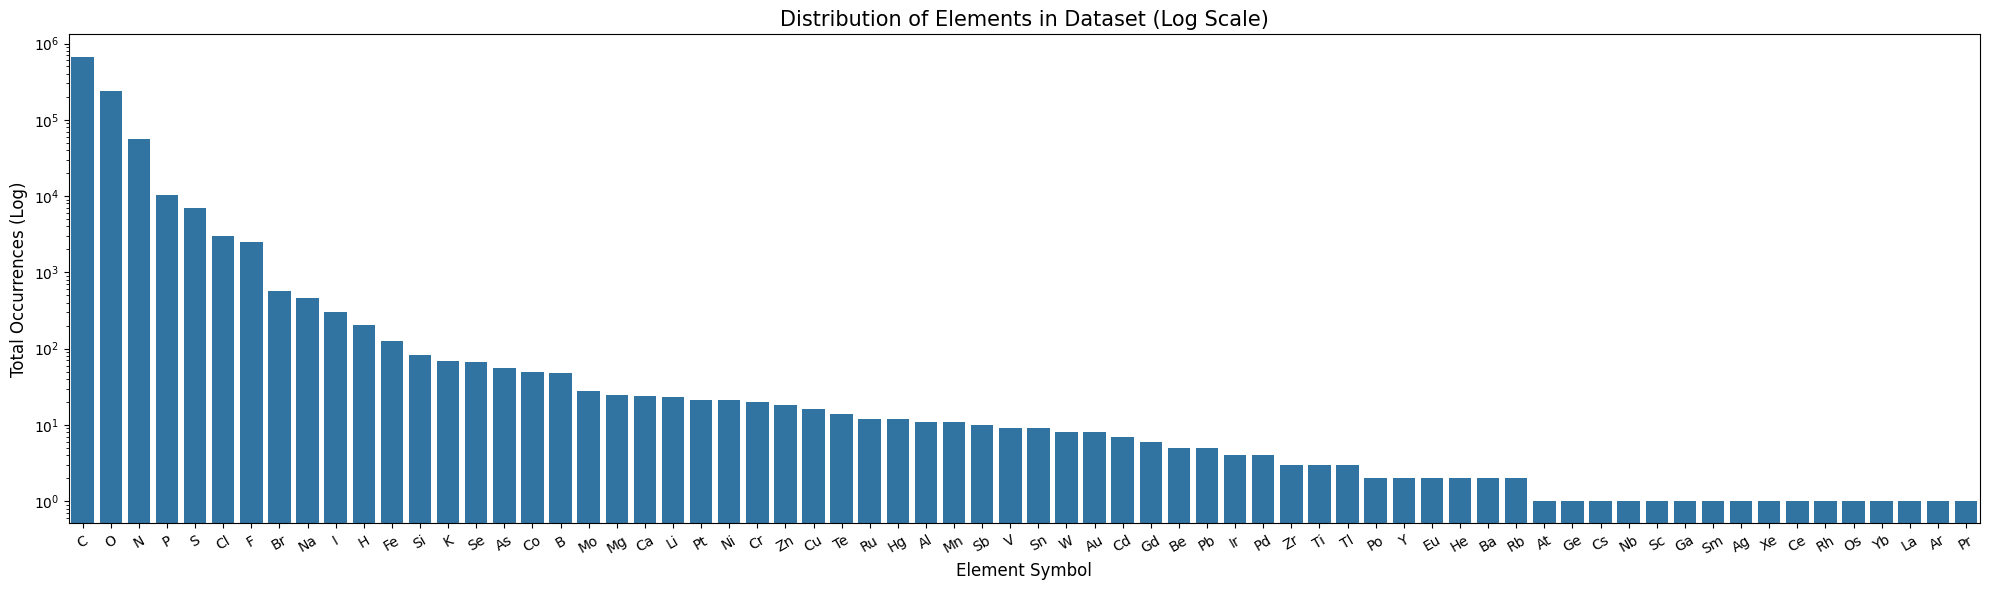

In [10]:
# 4. Visualize with Seaborn
plt.figure(figsize=(20, 6))

plot = sns.barplot(data=df, x="Element", y="Count")
plot.set_yscale("log")
plt.xticks(rotation=30)
plt.title("Distribution of Elements in Dataset (Log Scale)", fontsize=15)
plt.xlabel("Element Symbol", fontsize=12)
plt.ylabel("Total Occurrences (Log)", fontsize=12)
plt.tight_layout()

In [11]:
degrees , aromatics, rings = [],[],[]
for data in train_data:
    degrees.extend(data.x[:, 2].tolist())
    aromatics.extend(data.x[:, -2].tolist())
    rings.extend(data.x[:, -1].tolist())

degree_count, aromatic_count, ring_count = Counter(degrees), Counter(aromatics), Counter(rings)

In [12]:
stats = [
    ("NODE DEGREES", degree_count),
    ("AROMATICITY", aromatic_count),
    ("RING MEMBERS", ring_count)
]

for title, count_dict in stats:
    print(f"\n--- {title} ---")
    print(f"{'Value':<8} | {'Count':<10}")
    print("-" * 22)
    # Sorting by key so the values (0, 1, 2...) appear in order
    for val in sorted(count_dict.keys()):
        print(f"{str(val):<8} | {count_dict[val]:<10,}")


--- NODE DEGREES ---
Value    | Count     
----------------------
0        | 1,366     
1        | 88,513    
2        | 175,224   
3        | 286,279   
4        | 443,532   
6        | 14        

--- AROMATICITY ---
Value    | Count     
----------------------
0        | 826,336   
1        | 168,592   

--- RING MEMBERS ---
Value    | Count     
----------------------
0        | 613,924   
1        | 381,004   


In [13]:
hybridization = []
hybrid_labels = {
    0: "Unspecified",
    1: "S",
    2: "SP",
    3: "SP2",
    4: "SP3",
    5: "SP3D",
    6: "SP3D2",
    7: "Other",
}
counts = Counter([h for d in train_data for h in d.x[:, 6].tolist()])
for k, v in counts.most_common():
    label = hybrid_labels.get(k, "Other")
    print(f"{label:<12}: {v:,}")

SP3         : 587,601
SP2         : 405,185
SP          : 1,218
S           : 851
SP3D        : 47
SP3D2       : 20
Unspecified : 6


## Edge Features

In [14]:
bond_types , stereos, conjugateds = [],[],[]
for data in train_data:
    bond_types.extend(data.edge_attr[:, 0].tolist())
    stereos.extend(data.edge_attr[:, 1].tolist())
    conjugateds.extend(data.edge_attr[:, 2].tolist())

bond_count, stereo_count, conjugated_count = Counter(bond_types), Counter(stereos), Counter(conjugateds)
bond_names = {
    1 : "UNSPECIFIED",
    2 : "SINGLE",
    3 : "DOUBLE",
    12 : "FIVEANDAHALF"
}
bond_count = {bond_names[k]:v for k,v in bond_count.items()}

### Structural summary
 - Molecules are small, dense, cyclic
 - Chemistry is local and regular
 - Graphs are not deep, not heterogeneous

### Feature summary
Extreme imbalance, but:
- dominant categories are chemically meaningful 
- rare categories are safely ignorable but should not be dropped
- Boolean features (ring, aromatic) are high signal

### Text alignment

caption length weakly correlates with graph size


# Text stuff

In [27]:
train_data[0].description

"The molecule is tetraanion of ADP-D-ribose 2'-phosphate. It has a role as a human metabolite. It is a conjugate base of an ADP-D-ribose 2'-phosphate."

In [23]:
desc_lenghts = []
for d in train_data:
    desc_lenghts.append(len(d.description))
np.percentile(desc_lenghts,[90, 95, 99])

array([452.  , 525.65, 669.  ])

In [26]:
tokenizer = AutoTokenizer.from_pretrained("seyonec/ChemBERTa-zinc-base-v1")
lengths = []
for g in train_data:
    tokens = tokenizer(g.description)["input_ids"]
    lengths.append(len(tokens))

np.percentile(lengths, [90, 95, 99])


Token indices sequence length is longer than the specified maximum sequence length for this model (518 > 512). Running this sequence through the model will result in indexing errors


array([442.  , 514.  , 654.93])

In [29]:
tokenizer("This molecule is")["input_ids"]

[0, 56, 76, 77, 87, 225, 81, 83, 80, 73, 71, 89, 80, 73, 225, 77, 87, 2]